<a href="https://colab.research.google.com/github/ethanpetersen00-create/Python_Final_Project/blob/main/Python_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Suicide and the World Economy
Suicide in the 21st century is a big problem, and many people and institutions want to know how to prevent it. This requires an understanding of what causes people to take their own lives. Explanations for suicide are never one specific thing and are usually a myriad of life factors that contribute to severely poor mental health. While it's difficult to discover ultimate explanations for suicidal thoughts and behavior, we can start with the basics by looking at who is committing suicide and what kinds of enviornments they are in. We'll particularly try to see how much economic factors play a large a role, by seeing if poorer countries have higher suicide rates.

##Data
The dataset for this analysis comes from the World Health Organization and the World Bank, and was gathered together by Kaggle user Samar Talwar. The data contains suicide rates for 185 countries for each year from 2000 to 2021. It also has separate rates for males and females for each year and country as well as each country's GDP(in US dollars) and population.

In [26]:
import pandas as pd
df = pd.read_csv('global_suicide_rates_real_who_worldbank[1].csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18315 entries, 0 to 18314
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   country                   18315 non-null  object 
 1   country_code              18315 non-null  object 
 2   year                      18315 non-null  int64  
 3   sex                       18315 non-null  object 
 4   age_bracket               18315 non-null  object 
 5   suicide_rate_per_100k     18315 non-null  float64
 6   generation                18315 non-null  object 
 7   gdp_usd                   18000 non-null  float64
 8   gdp_per_capita_usd        18000 non-null  float64
 9   total_country_population  18315 non-null  float64
dtypes: float64(4), int64(1), object(5)
memory usage: 1.4+ MB


It looks like the data frame does not have GDP statistics for Cuba, Eritrea, North Korea, South Sudan, and Yemen. Since this analysis will focus heavily on economic indicators, we will drop these five countries.

In [33]:
#Checking null values
df[df.isna().any(axis=1)]
#Dropping countries with no GDP data.
df = df.dropna()
df.loc[df['country'] == 'United States']

,country,country_code,year,sex,age_bracket,suicide_rate_per_100k,generation,gdp_usd,gdp_per_capita_usd,total_country_population
17424,United States,USA,2000,both,all_ages,11.17,All Cohorts,1.025095e+13,36329.97,282162411
17425,United States,USA,2000,female,all_ages,4.54,All Cohorts,1.025095e+13,36329.97,282162411
17426,United States,USA,2000,male,all_ages,17.89,All Cohorts,1.025095e+13,36329.97,282162411
17427,United States,USA,2001,both,all_ages,11.55,All Cohorts,1.058193e+13,37133.62,284968955
17428,United States,USA,2001,female,all_ages,4.70,All Cohorts,1.058193e+13,37133.62,284968955
...,...,...,...,...,...,...,...,...,...,...
17518,United States,USA,2021,male,50-59,28.47,All Cohorts,2.372564e+13,71441.23,332100166
17519,United States,USA,2021,male,50-69,27.29,All Cohorts,2.372564e+13,71441.23,332100166
17520,United States,USA,2021,male,60-69,25.97,All Cohorts,2.372564e+13,71441.23,332100166
17521,United States,USA,2021,male,70plus,36.76,All Cohorts,2.372564e+13,71441.23,332100166


For gdp_usd, we'll divide by 1000000 to show the variable in millions of dollars and round to two decimal places. We'll also round gdp_per_capita_usd to two decimal places and remove decimal values for total_country_population.

In [30]:
df['gdp_per_capita_usd'] = df['gdp_per_capita_usd'].round(2)
df['total_country_population'] = (df['total_country_population']).astype(int)

Now, it probably won't do much good to do different data examinations on the different suicide rates year after year. So we'll aggregate the values into means for each country.

In [5]:
mean_suicide_rate = (df[df['sex'] == 'both'].groupby('country_code')['suicide_rate_per_100k'].mean().reset_index()
)
mean_gdp = df[df['sex'] == 'both'].groupby('country_code')['gdp_usd'].mean().reset_index()

mean_gdp_per_capita = df[df['sex'] == 'both'].groupby('country_code')['gdp_per_capita_usd'].mean().reset_index()

mean_population = df[df['sex'] == 'both'].groupby('country_code')['total_country_population'].mean().reset_index()

##Analyses
To start, we'll get some context by looking to see what countries have higher and lower suicides.

In [65]:
import plotly.express as px
fig1 = px.choropleth(
    data_frame = mean_suicide_rate,
    locations = 'country_code',
    locationmode = 'ISO-3',
    color = 'suicide_rate_per_100k',
    labels={'suicide_rate_per_100k': 'Suicides per 100K People'},
    color_continuous_scale = 'Reds'
)

fig1.update_layout(
    title={
        'text': 'National Suicide Rates',
        'x': 0.5,
        'xanchor': 'center'
    }
)

fig1.update_layout(
    autosize=False,
    width=1000,
    height=600
)

fig1.update_geos(
    projection_type='natural earth',
    fitbounds=False,
    lonaxis_range=[-180, 180],
    lataxis_range=[-90, 90]
)

fig1.show()

Already there are some interesting patterns. The Middle East and Northern Africa have the lowest suicide rates along with much of Latin America. The countries with the highest rates appear to be in Europe-espeically Eastern Europe-as well as some parts of Southern Africa and East Asia.
This discredits the idea that poorer countries have higher suicide rates.

An alternate explanation is that sociocultural factors have a higher impact on suicide. Indonesia and the Philippines have exceptionally low suicide rates and are very religious countries just like the other world regions with the lowest rates. Japan and South Korea have some of the highest suicide rates despite generally being considered rich countries. This may have to do with the social problems of being very unequal countries economically.

We'll now look visualize the data to see if there is any correlation between a country's GDP and its suicide rate. We'll also make a new data frame based on the means of the countries' statistics of the 20 year period.

Text(0, 0.5, 'GDP (Trillions of Dollars)')

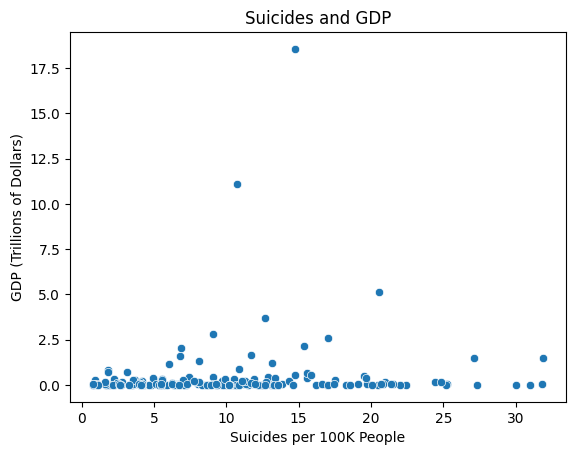

In [37]:
#Merging the aggregated data into combined_df
combined_df = pd.merge(mean_suicide_rate, mean_gdp, on='country_code')
combined_df = pd.merge(combined_df, mean_gdp_per_capita, on='country_code')
combined_df = pd.merge(combined_df, mean_population, on='country_code')

import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

ax = sns.scatterplot(x=combined_df['suicide_rate_per_100k'], y=combined_df['gdp_usd'])
plt.title('Suicides and GDP')

ax.yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f'{x/1e12:.1f}')
)

plt.xlabel('Suicides per 100K People')
plt.ylabel('GDP (Trillions of Dollars)')

This is difficult to interpret based on a couple outliers in GDP(probably the United States and China). We'll remove them from the scatter plot:

Text(0, 0.5, 'GDP (Trillions of Dollars)')

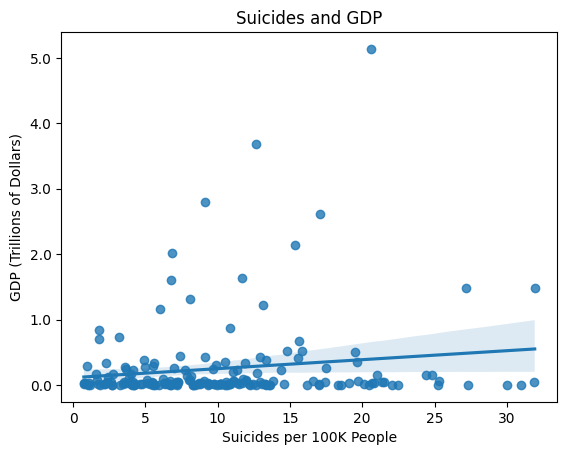

In [38]:
filtered_df = combined_df.drop(mean_gdp['gdp_usd'].nlargest(2).index)

ax = sns.regplot(x=filtered_df['suicide_rate_per_100k'], y=filtered_df['gdp_usd'])
plt.title('Suicides and GDP')

ax.yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f'{x/1e12:.1f}')
)

plt.xlabel('Suicides per 100K People')
plt.ylabel('GDP (Trillions of Dollars)')

Interestingly there is actually a slight positive correlation between GDP and suicides. Though the correlation is so low and so weak that it may be more accurate to say there is no real correlation at all. Of course, many countries will naturally have higher GDPs just because they have larger populations. We'll now look at GDP per capita:

Text(0, 0.5, 'GDP per Capita')

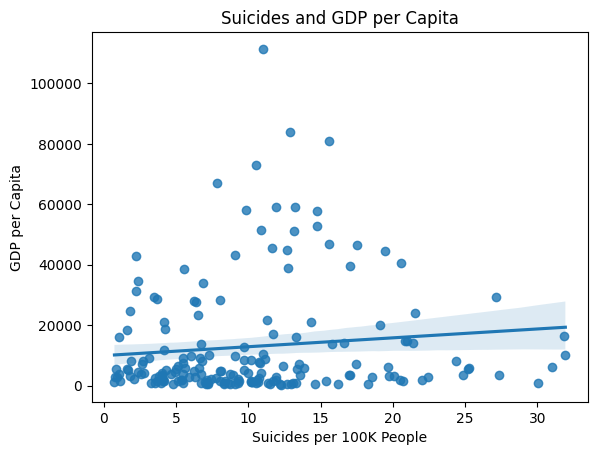

In [39]:
sns.regplot(x=combined_df['suicide_rate_per_100k'], y=combined_df['gdp_per_capita_usd'])

plt.title('Suicides and GDP per Capita')
plt.xlabel('Suicides per 100K People')
plt.ylabel('GDP per Capita')

Still, the correlation is slightly positive but very weak. The following bubble chart shows the the same data with bubble size proportional to the country's population, and population doesn't seem to have a correlation with suicide rates or GDP per capita. This means that there aren't a few exceptionally small or large countries skewing the data.

In [44]:
fig = px.scatter(x=combined_df['suicide_rate_per_100k'], y=combined_df['gdp_per_capita_usd'],
                 size=combined_df['total_country_population'],
                 hover_name=combined_df['country_code'],
                 title='Suicides, Population, and GDP per Capita',
                 labels={
        'gdp_per_capita_usd': 'GDP',
        'suicide_rate_per_100k': 'Suicides per 100K People',
        'total_country_population': 'Population'
    }
)

fig.update_layout(
    xaxis_title='GDP',
    yaxis_title='Suicides per 100K People'
)

fig.show()

##Male and Female Suicides
Another thing worth discussing is how male suicide rates usually tend to be higher than female suicide rates for reasons that aren't clear. One idea is the classical expectations for men to work hard and be productive in order to provide for a family. Since the original data set provides them, we'll separate the overall suicide rates for males and females and see if the correlations differ based on GDP per capita.

Text(0, 0.5, 'GDP per Capita')

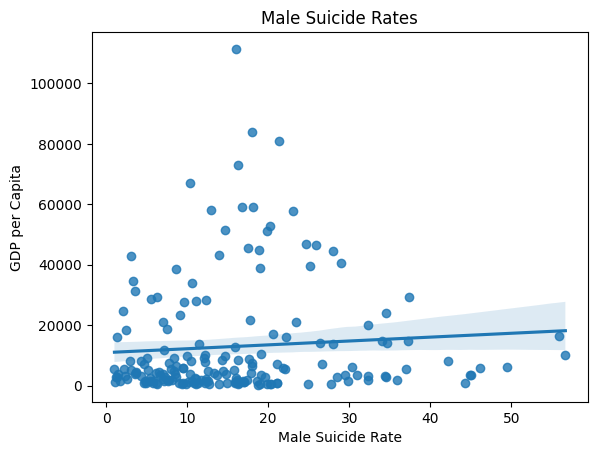

In [45]:
#Aggregating male suicide rates
male_suicide_rate = (df[df['sex'] == 'male'].groupby('country_code')['suicide_rate_per_100k']
    .mean().reset_index().rename(columns={'suicide_rate_per_100k': 'male_suicide_rate'})
)
#Aggregating female suicide rates
female_suicide_rate = (df[df['sex'] == 'female'].groupby('country_code')['suicide_rate_per_100k']
    .mean().reset_index().rename(columns={'suicide_rate_per_100k': 'female_suicide_rate'})
)
#Merging with combined_df
combined_df = pd.merge(combined_df, male_suicide_rate, on = 'country_code')
combined_df = pd.merge(combined_df, female_suicide_rate, on = 'country_code')

sns.regplot(x=combined_df['male_suicide_rate'], y=combined_df['gdp_per_capita_usd'])

plt.title('Male Suicide Rates')
plt.xlabel('Male Suicide Rate')
plt.ylabel('GDP per Capita')

Text(0, 0.5, 'GDP per Capita')

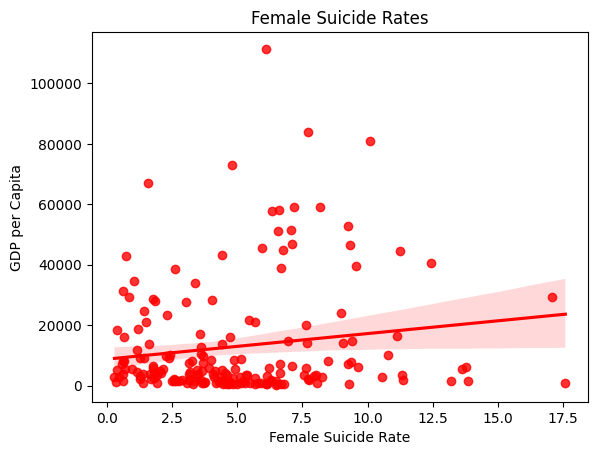

In [67]:
sns.regplot(x=combined_df['female_suicide_rate'], y=combined_df['gdp_per_capita_usd'],
            color = 'red')

plt.title('Female Suicide Rates')
plt.xlabel('Female Suicide Rate')
plt.ylabel('GDP per Capita')

As shown, while male suicide rates are usually higher than those of females, the correlations are still very weak. However, female suicide rates tend to rise with GDP somewhat more so than male suicide rates do. Although, the correlations are so weak it's hard to make any definitive conclusions.

We could look at the differences between male and female rates in each country and see how it correlates to the country's economy:

Text(0, 0.5, 'GDP per Capita')

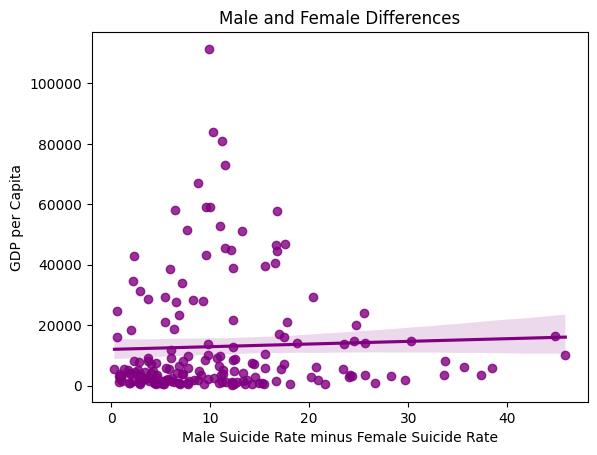

In [68]:
sns.regplot(x=(combined_df['male_suicide_rate'] - combined_df['female_suicide_rate']),
            y=combined_df['gdp_per_capita_usd'],
            color='purple')

plt.title('Male and Female Differences')
plt.xlabel('Male Suicide Rate minus Female Suicide Rate')
plt.ylabel('GDP per Capita')

In [66]:
combined_df['male_female_ratio'] = combined_df['male_suicide_rate']
- combined_df['female_suicide_rate']

fig2 = px.choropleth(
    data_frame = combined_df,
    locations = 'country_code',
    locationmode = 'ISO-3',
    color = (combined_df['male_female_ratio']),
labels={'male_female_ratio': 'Difference between Male and Female Rates'},
    color_continuous_scale = 'Purples'
)

fig2.update_layout(
    autosize=False,
    width=1000,
    height=600
)

fig2.update_geos(
    projection_type='natural earth',
    fitbounds=False,
    lonaxis_range=[-180, 180],
    lataxis_range=[-90, 90]
)

fig2.update_layout(
    title={
        'text': 'Male vs Female Suicide Rates',
        'x': 0.5,
        'xanchor': 'center'
    }
)

fig2.show()

There is still little to no correlation. However, although male suicide rates are higher than female suicide rates in every country, we see that the countries where male suicides are most higher than those of females are poorer countries. Rich countries have less difference between male and female suicide rates although there are plenty of poor countries with little difference between the genders too.

We can also see from the map that countries with higher suicide rates overall tend to also be countries where the male suicide rate is much higher than the female suicide rate. The countries that seem to have the most difference are Russia, Kazakhstan, Mongolia, and some Eastern European countries, none of which are very wealthy relative to the world.

##Conclusion
We can pretty confidently say that a country's GDP has little to no effect on the suicide rates. However, this doesn't mean that the country's economy has no effect on suicides at all. What may be a bigger factor is inequality in a country. It's one thing to be poor or have a low-income, but when other people in your country or community are rich and seem to be much better off, that can really take a toll on mental health. The differences between male and female suicide rates are also not fully understood but it appears GDP does not affect male and female suicides too differently and the starkest differences between the two genders come from a few poor countries.

This is an issue that needs more research into what economic parameters contribute to poor mental health and suicides, but the idea people from richer countries are less likely to commit suicide than people from poorer ones seem to have no merit.
